---
# **Cuaderno 2:**  Analisis de datos de ICGC
---
* Author: Melissa Ormeño; Alexis Salas
* Laboratory: Cancer Molecular Dynamics
* Date: Agosto 2025

**Aims:**

* Analiza los datos obtenidos al filtrar por gen un archivo de mutaciones de la base de datos del ICGC

### Librerias

In [2]:
import pandas as pd
import requests
import re
import matplotlib.pyplot as plt

### Cargar archivo de mutaciones

El archivo proviene del cuaderno 01_Cancer_mutations

In [59]:
#Nombre grupo de genes
grupo = "kinase"
#Ruta 
ruta = "../data/Cancer/mut_cancer_{0}.csv".format(grupo)
#Cargar archivo
df = pd.read_csv(ruta)
df = df.drop_duplicates()
#Datos
print(f"tamaño: \n{df.shape}")
print(f"valores nulos: \n{df.isnull().sum()}")


df.head(2)

tamaño: 
(689519, 8)
valores nulos: 
icgc_donor_id               0
uniprot_id                  0
gen_name                    0
aa_mutation            558734
tipo_cancer                 0
transcript_affected         0
verification_status         0
consequence_type            0
dtype: int64


,icgc_donor_id,uniprot_id,gen_name,aa_mutation,tipo_cancer,transcript_affected,verification_status,consequence_type
0,DO37659,Q5JZY3,EPHA10,E34K,Piel,ENST00000319637,not tested,missense_variant
1,DO37659,Q5JZY3,EPHA10,E34K,Piel,ENST00000373048,not tested,missense_variant


## 1. Procesar archivo de mutaciones


In [60]:
df_cancer = df.dropna()
print(f"Tamaño: {df_cancer.shape}")
print(f"Número de pacientes: {df_cancer['icgc_donor_id'].nunique()}")
print(f"Número de genes: {df_cancer['gen_name'].nunique()}")

Tamaño: (130785, 8)
Número de pacientes: 8058
Número de genes: 133


In [61]:
#Crea un data frame donde solo esten los datos que han sido verificados y que no esten testeados
df_verificado = df_cancer.loc[(df_cancer['verification_status'] == 'tested and verified') | (df_cancer['verification_status'] == 'not tested')]
print(f"Verificacion (df_cancer): {df_cancer['verification_status'].unique()}")
print(f"Verificacion (df_verificado): {df_verificado['verification_status'].unique()}")
print(f"Tamaño: {df_verificado.shape}")

Verificacion (df_cancer): ['not tested' 'tested and verified' 'tested and verified to be false']
Verificacion (df_verificado): ['not tested' 'tested and verified']
Tamaño: (130779, 8)


In [62]:
# elimina las mutaciones synonymous (silenciosas) 
df_consequence=df_verificado[df_verificado['consequence_type'] != 'synonymous_variant'].reset_index(drop=True)
print(f"Tamaño: {df_consequence.shape}")
print(f"Tipos de mutación: \n{df_consequence['consequence_type'].unique()}")


Tamaño: (96840, 8)
Tipos de mutación: 
['missense_variant' 'stop_gained' 'frameshift_variant' 'stop_lost'
 'start_lost' 'disruptive_inframe_insertion' 'inframe_insertion'
 'inframe_deletion' 'stop_retained_variant' 'disruptive_inframe_deletion'
 'initiator_codon_variant']


In [63]:
#Numero de mutaciones unicas y pacientes 
print(f"Número de mutaciones: {df_consequence['aa_mutation'].nunique()}")
print(f"Número de pacientes: {df_consequence['icgc_donor_id'].nunique()}")

Número de mutaciones: 39493
Número de pacientes: 7258


## 2. Clasificación de mutaciones por Dominio

In [64]:
#uniprot_ids = ["O00238"]
uniprot_ids = df_consequence["uniprot_id"].unique()

def get_features(uniprot_ids):

    features_dict = {}
    types = ["Signal", "Transmembrane",  "Domain"]
    
    """ Es decision del usuario de dejar "Topological domain", ya que este incluye tambien al dominio quinasa.
    Se quitaron las cadenas de "Region" y "Chain", ya que no se consideran dominios como tal. """

    for uniprot_id in uniprot_ids: 
        response = requests.get(f'https://rest.uniprot.org/uniprotkb/{uniprot_id}.json')
    
        if response.status_code == 200:
            json_data = response.json()
            gen_name = json_data['genes'][0]['geneName']['value']  # Extrae el nombre del gen
            features = json_data.get("features")

        features_dict[gen_name] = []
        
        for f in features:
            f_type = f.get("type")
            if f_type in types:
                f_start = f.get("location").get("start").get("value")
                f_end = f.get("location").get("end").get("value")
                f_description = f.get("description")
                f_domain_name = f_type if not f_description else f"{f_type}_{f_description}"
    
                # Guardar 
                features_dict[gen_name].append({
                    #"uniprot_id": uniprot_id,
                    #"gen_name": gen_name,
                    "Dominio": f_domain_name,
                    "Start": int(f_start),
                    "End": int(f_end),
                   
                })

    return features_dict

data = get_features(uniprot_ids)

def clasificar_mutacion(row):
   
    gene = row['gen_name']
    mutation = row['aa_mutation']

    if gene in data:

        position = int(''.join(filter(str.isdigit, mutation)))
        
        # Recorrer la lista de dominios de ese gen
        for dominio in data[gene]:
            start = dominio["Start"]
            end = dominio["End"]
            nombre = dominio["Dominio"]
            
            if start <= position <= end:
            
                return pd.Series([nombre, f"{start}-{end}"])  # Dominio y rango

    return pd.Series(["Otro", None]) 

df_consequence[['Dominio', "Rango"]] = df_consequence.apply(clasificar_mutacion, axis=1)
df_consequence

,icgc_donor_id,uniprot_id,gen_name,aa_mutation,tipo_cancer,transcript_affected,verification_status,consequence_type,Dominio,Rango
0,DO37659,Q5JZY3,EPHA10,E34K,Piel,ENST00000319637,not tested,missense_variant,Otro,None
1,DO37659,Q5JZY3,EPHA10,E34K,Piel,ENST00000373048,not tested,missense_variant,Otro,None
2,DO37659,Q5JZY3,EPHA10,E34K,Piel,ENST00000427468,not tested,missense_variant,Otro,None
3,DO37507,Q5JZY3,EPHA10,P545H,Piel,ENST00000373048,not tested,missense_variant,Domain_Fibronectin type-III 2,456-554
4,DO37507,Q5JZY3,EPHA10,P40H,Piel,ENST00000540011,not tested,missense_variant,Domain_Eph LBD,35-216
...,...,...,...,...,...,...,...,...,...,...
96835,DO449,P51813,BMX,R670W,Vejiga,ENST00000348343,not tested,missense_variant,Domain_Protein kinase,417-675
96836,DO449,P51813,BMX,R670W,Vejiga,ENST00000357607,not tested,missense_variant,Domain_Protein kinase,417-675
96837,DO528,P51813,BMX,N340K,Vejiga,ENST00000342014,not tested,missense_variant,Domain_SH2,296-392
96838,DO528,P51813,BMX,N340K,Vejiga,ENST00000357607,not tested,missense_variant,Domain_SH2,296-392


In [67]:
df_consequence.groupby("Dominio")["Rango"].unique()

Dominio
Domain_CARD                                                      [432-524]
Domain_COR                                           [844-1036, 1546-1740]
Domain_CRIB                                                      [454-466]
Domain_Cadherin                                                  [168-272]
Domain_Death                      [13-94, 20-104, 41-106, 27-106, 583-669]
                                               ...                        
Domain_UBA                                                       [958-996]
Domain_WIF                                                        [66-194]
Otro                                                                [None]
Signal                   [1-33, 1-26, 1-21, 1-23, 1-20, 1-16, 1-18, 1-1...
Transmembrane_Helical    [566-586, 151-171, 378-398, 529-549, 542-565, ...
Name: Rango, Length: 65, dtype: object

## 3. Visualización de resultados

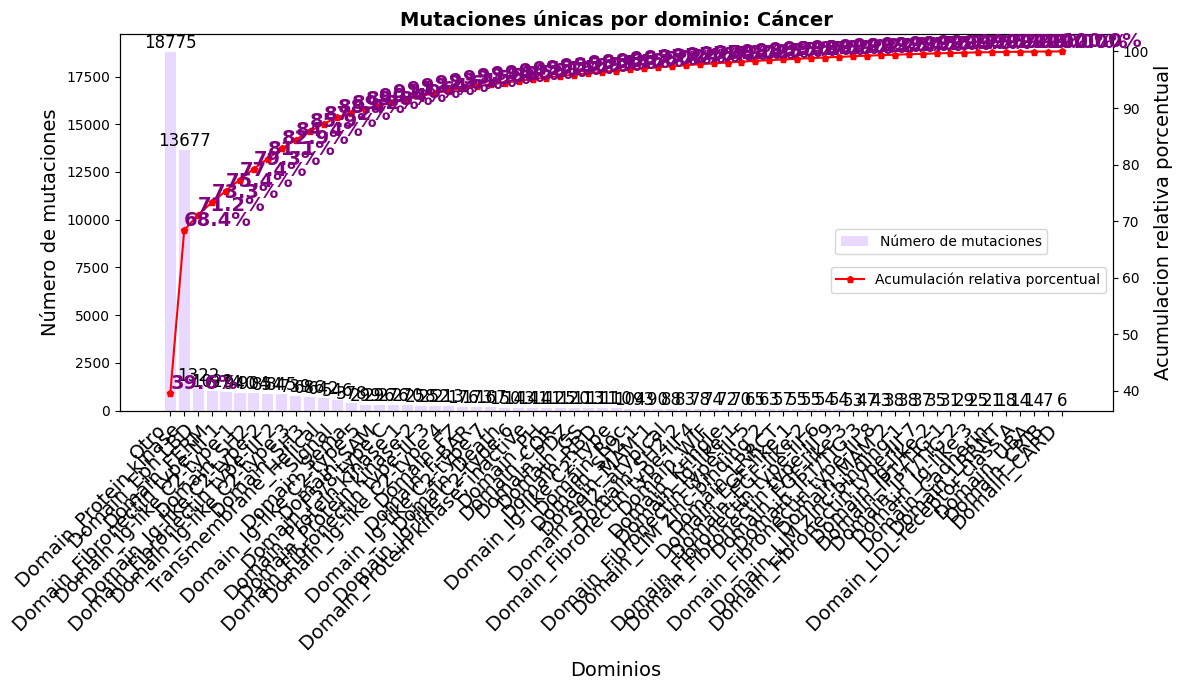

In [66]:
#PARAMETROS GENRALES
df = df_consequence #DATAFRAME A UTILIZAR
count = "aa_mutation" #COLUMNA QUE SE VA A CONTAR O SUMAR (eje Y)
grupo = "Dominio" #barras
mutation_counts = df.groupby(grupo, as_index=False)[count].nunique() #OPERACION 

#PARAMETROS DE ETIQUETA
ylabel = 'Número de mutaciones' # Etiqueta eje y
ylabel2 = 'Acumulacion relativa porcentual' # Etiqueta eje 2
set_title = 'Mutaciones únicas por dominio: Cáncer' # Titulo del grafico
set_xlabel = 'Dominios' # Titulo eje X
leyenda_2 = 'Acumulación relativa porcentual' # Nombre leyenda eje 2
leyenda_count = 'Número de mutaciones' # Nombre leyenda eje 1

#PARAMETROS COLORES
color_bar = "#e9d8ffff"
color_linea = "red"
numero_acumulacion = 'purple'

#PARAMETRO DE GUARDADO
GUARDAR_GRAFICO = False
FORMATO_IMAGEN = "png"  # Cambiar a "svg" si se quiere otro formato (png y svg deben estar en minuscula)
DPI = 600  # Se usará solo si FORMATO_IMAGEN == "png"
NOMBRE_IMAGEN = "mut_missense_tgfb"
RUTA = f"../run/imagenes/{NOMBRE_IMAGEN}_.{FORMATO_IMAGEN}"


# Ordenar las mutaciones de mayor a menor
mutation_counts.sort_values(by=count, ascending=False, inplace=True)
mutation_counts.reset_index(drop=True, inplace=True)

# Calcular la acumulación relativa porcentual
mutation_counts['relativa_acum_porcentual'] = mutation_counts[count].cumsum() / mutation_counts[count].sum() * 100

# Crear la figura y los ejes
fig, ax = plt.subplots(figsize=(12, 7))  # Ajusta el tamaño de la figura

# Gráfico de barras para el número de mutaciones
bars = ax.bar(mutation_counts[grupo], mutation_counts[count])

# Gráfico de barras para la cantidad de mutaciones por tipo de cáncer
ax.bar(mutation_counts[grupo], mutation_counts[count], color=color_bar, label=leyenda_count)

# Crear un segundo eje y para la línea de acumulación relativa porcentual
ax2 = ax.twinx()
ax2.plot(mutation_counts.index, mutation_counts['relativa_acum_porcentual'], color=color_linea, marker="p", ms=5, label=leyenda_2)

# Agregar etiquetas con el número de mutaciones encima de las barras
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, height, f'{int(height)}', ha='center', va='bottom', color='black', fontsize=12)

# Agregar etiquetas con el porcentaje acumulado en los puntos de la línea
for i, value in enumerate(mutation_counts["relativa_acum_porcentual"]):
    ax2.text(i, value, f'{value:.1f}%', ha='left', va='bottom', color=numero_acumulacion, fontsize=14,fontweight  = 'bold')
# Ajustar límites y etiquetas
ax.set_ylabel(ylabel, fontsize=14)
ax2.set_ylabel(ylabel2, fontsize=14)
ax.set_title(set_title, fontsize=14, fontweight = "bold")
ax.set_xlabel(set_xlabel, fontsize=14)

# Ajustar las etiquetas del eje x
ax.set_xticks(range(len(mutation_counts[grupo])))  # Colocar las etiquetas en las posiciones correctas
ax.set_xticklabels(mutation_counts[grupo], rotation=45, ha="right", fontsize=14)  # Rotar las etiquetas y alinearlas a la derecha

# Añadir leyendas
ax.legend(loc='best', bbox_to_anchor=(0.941, 0.5))  # Leyenda del primer eje
ax2.legend(loc='best', bbox_to_anchor=(1, 0.4))  # Leyenda del segundo eje, un poco más abajo

# Ajustar el diseño para evitar solapamientos
plt.tight_layout()

# Guardar el gráfico en formato SVG antes de mostrarlo
if GUARDAR_GRAFICO:
    if FORMATO_IMAGEN == "png":
        plt.savefig(RUTA, format="png", dpi=DPI)
    else:
        plt.savefig(RUTA, format=FORMATO_IMAGEN)

plt.show()


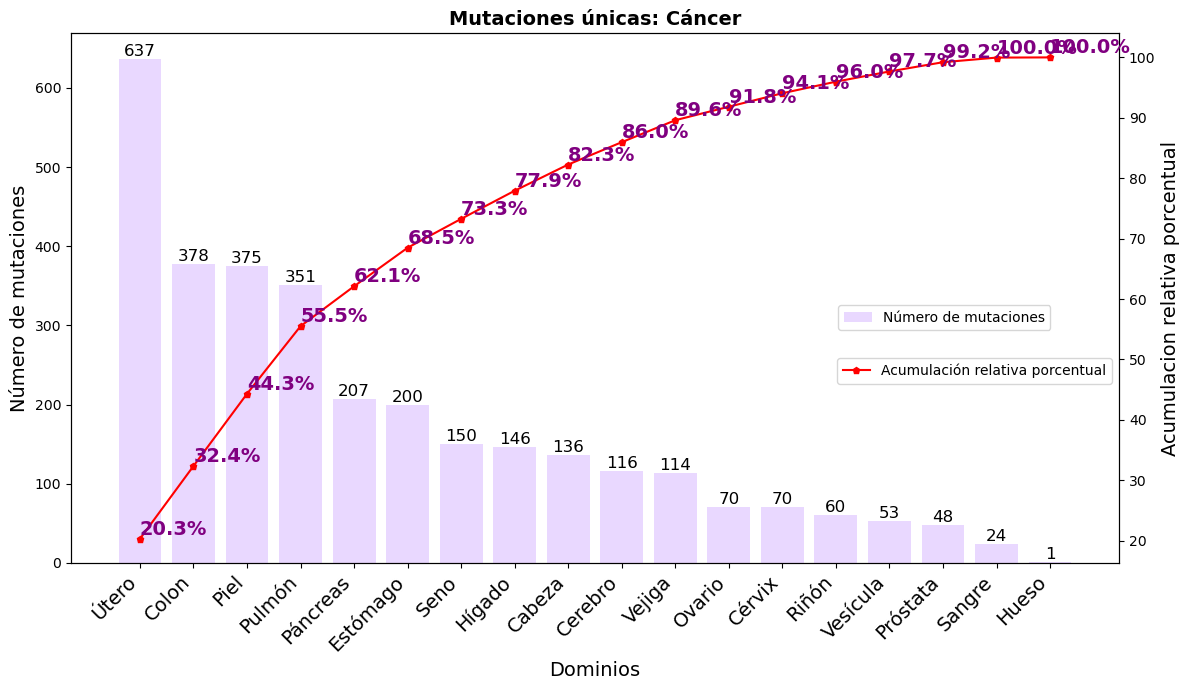

In [29]:
#PARAMETROS GENRALES
df = df_consequence #DATAFRAME A UTILIZAR
count = "aa_mutation" #COLUMNA QUE SE VA A CONTAR O SUMAR (eje Y)
grupo = "tipo_cancer" #barras
mutation_counts = df.groupby(grupo, as_index=False)[count].nunique() #OPERACION 

#PARAMETROS DE ETIQUETA
ylabel = 'Número de mutaciones' # Etiqueta eje y
ylabel2 = 'Acumulacion relativa porcentual' # Etiqueta eje 2
set_title = 'Mutaciones únicas: Cáncer' # Titulo del grafico
set_xlabel = 'Dominios' # Titulo eje X
leyenda_2 = 'Acumulación relativa porcentual' # Nombre leyenda eje 2
leyenda_count = 'Número de mutaciones' # Nombre leyenda eje 1

#PARAMETROS COLORES
color_bar = "#e9d8ffff"
color_linea = "red"
numero_acumulacion = 'purple'

#PARAMETRO DE GUARDADO
GUARDAR_GRAFICO = False
FORMATO_IMAGEN = "png"  # Cambiar a "svg" si se quiere otro formato (png y svg deben estar en minuscula)
DPI = 600  # Se usará solo si FORMATO_IMAGEN == "png"
NOMBRE_IMAGEN = "mut_missense_tgfb"
RUTA = f"../run/imagenes/{NOMBRE_IMAGEN}_.{FORMATO_IMAGEN}"


# Ordenar las mutaciones de mayor a menor
mutation_counts.sort_values(by=count, ascending=False, inplace=True)
mutation_counts.reset_index(drop=True, inplace=True)

# Calcular la acumulación relativa porcentual
mutation_counts['relativa_acum_porcentual'] = mutation_counts[count].cumsum() / mutation_counts[count].sum() * 100

# Crear la figura y los ejes
fig, ax = plt.subplots(figsize=(12, 7))  # Ajusta el tamaño de la figura

# Gráfico de barras para el número de mutaciones
bars = ax.bar(mutation_counts[grupo], mutation_counts[count])

# Gráfico de barras para la cantidad de mutaciones por tipo de cáncer
ax.bar(mutation_counts[grupo], mutation_counts[count], color=color_bar, label=leyenda_count)

# Crear un segundo eje y para la línea de acumulación relativa porcentual
ax2 = ax.twinx()
ax2.plot(mutation_counts.index, mutation_counts['relativa_acum_porcentual'], color=color_linea, marker="p", ms=5, label=leyenda_2)

# Agregar etiquetas con el número de mutaciones encima de las barras
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, height, f'{int(height)}', ha='center', va='bottom', color='black', fontsize=12)

# Agregar etiquetas con el porcentaje acumulado en los puntos de la línea
for i, value in enumerate(mutation_counts["relativa_acum_porcentual"]):
    ax2.text(i, value, f'{value:.1f}%', ha='left', va='bottom', color=numero_acumulacion, fontsize=14,fontweight  = 'bold')
# Ajustar límites y etiquetas
ax.set_ylabel(ylabel, fontsize=14)
ax2.set_ylabel(ylabel2, fontsize=14)
ax.set_title(set_title, fontsize=14, fontweight = "bold")
ax.set_xlabel(set_xlabel, fontsize=14)

# Ajustar las etiquetas del eje x
ax.set_xticks(range(len(mutation_counts[grupo])))  # Colocar las etiquetas en las posiciones correctas
ax.set_xticklabels(mutation_counts[grupo], rotation=45, ha="right", fontsize=14)  # Rotar las etiquetas y alinearlas a la derecha

# Añadir leyendas
ax.legend(loc='best', bbox_to_anchor=(0.941, 0.5))  # Leyenda del primer eje
ax2.legend(loc='best', bbox_to_anchor=(1, 0.4))  # Leyenda del segundo eje, un poco más abajo

# Ajustar el diseño para evitar solapamientos
plt.tight_layout()

# Guardar el gráfico en formato SVG antes de mostrarlo
if GUARDAR_GRAFICO:
    if FORMATO_IMAGEN == "png":
        plt.savefig(RUTA, format="png", dpi=DPI)
    else:
        plt.savefig(RUTA, format=FORMATO_IMAGEN)

plt.show()


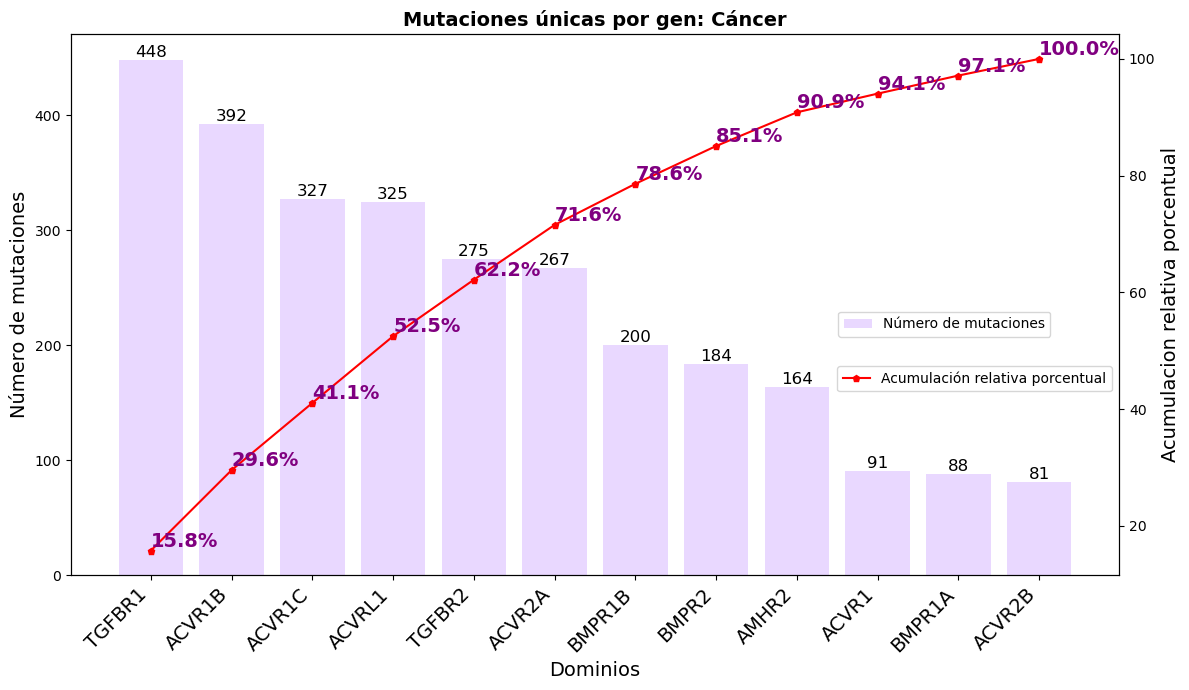

In [30]:
#PARAMETROS GENRALES
df = df_consequence #DATAFRAME A UTILIZAR
count = "aa_mutation" #COLUMNA QUE SE VA A CONTAR O SUMAR (eje Y)
grupo = "gen_name" #barras
mutation_counts = df.groupby(grupo, as_index=False)[count].nunique() #OPERACION 

#PARAMETROS DE ETIQUETA
ylabel = 'Número de mutaciones' # Etiqueta eje y
ylabel2 = 'Acumulacion relativa porcentual' # Etiqueta eje 2
set_title = 'Mutaciones únicas por gen: Cáncer' # Titulo del grafico
set_xlabel = 'Dominios' # Titulo eje X
leyenda_2 = 'Acumulación relativa porcentual' # Nombre leyenda eje 2
leyenda_count = 'Número de mutaciones' # Nombre leyenda eje 1

#PARAMETROS COLORES
color_bar = "#e9d8ffff"
color_linea = "red"
numero_acumulacion = 'purple'

#PARAMETRO DE GUARDADO
GUARDAR_GRAFICO = False
FORMATO_IMAGEN = "png"  # Cambiar a "svg" si se quiere otro formato (png y svg deben estar en minuscula)
DPI = 600  # Se usará solo si FORMATO_IMAGEN == "png"
NOMBRE_IMAGEN = "mut_missense_tgfb"
RUTA = f"../run/imagenes/{NOMBRE_IMAGEN}_.{FORMATO_IMAGEN}"


# Ordenar las mutaciones de mayor a menor
mutation_counts.sort_values(by=count, ascending=False, inplace=True)
mutation_counts.reset_index(drop=True, inplace=True)

# Calcular la acumulación relativa porcentual
mutation_counts['relativa_acum_porcentual'] = mutation_counts[count].cumsum() / mutation_counts[count].sum() * 100

# Crear la figura y los ejes
fig, ax = plt.subplots(figsize=(12, 7))  # Ajusta el tamaño de la figura

# Gráfico de barras para el número de mutaciones
bars = ax.bar(mutation_counts[grupo], mutation_counts[count])

# Gráfico de barras para la cantidad de mutaciones por tipo de cáncer
ax.bar(mutation_counts[grupo], mutation_counts[count], color=color_bar, label=leyenda_count)

# Crear un segundo eje y para la línea de acumulación relativa porcentual
ax2 = ax.twinx()
ax2.plot(mutation_counts.index, mutation_counts['relativa_acum_porcentual'], color=color_linea, marker="p", ms=5, label=leyenda_2)

# Agregar etiquetas con el número de mutaciones encima de las barras
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, height, f'{int(height)}', ha='center', va='bottom', color='black', fontsize=12)

# Agregar etiquetas con el porcentaje acumulado en los puntos de la línea
for i, value in enumerate(mutation_counts["relativa_acum_porcentual"]):
    ax2.text(i, value, f'{value:.1f}%', ha='left', va='bottom', color=numero_acumulacion, fontsize=14,fontweight  = 'bold')
# Ajustar límites y etiquetas
ax.set_ylabel(ylabel, fontsize=14)
ax2.set_ylabel(ylabel2, fontsize=14)
ax.set_title(set_title, fontsize=14, fontweight = "bold")
ax.set_xlabel(set_xlabel, fontsize=14)

# Ajustar las etiquetas del eje x
ax.set_xticks(range(len(mutation_counts[grupo])))  # Colocar las etiquetas en las posiciones correctas
ax.set_xticklabels(mutation_counts[grupo], rotation=45, ha="right", fontsize=14)  # Rotar las etiquetas y alinearlas a la derecha

# Añadir leyendas
ax.legend(loc='best', bbox_to_anchor=(0.941, 0.5))  # Leyenda del primer eje
ax2.legend(loc='best', bbox_to_anchor=(1, 0.4))  # Leyenda del segundo eje, un poco más abajo

# Ajustar el diseño para evitar solapamientos
plt.tight_layout()

# Guardar el gráfico en formato SVG antes de mostrarlo
if GUARDAR_GRAFICO:
    if FORMATO_IMAGEN == "png":
        plt.savefig(RUTA, format="png", dpi=DPI)
    else:
        plt.savefig(RUTA, format=FORMATO_IMAGEN)

plt.show()


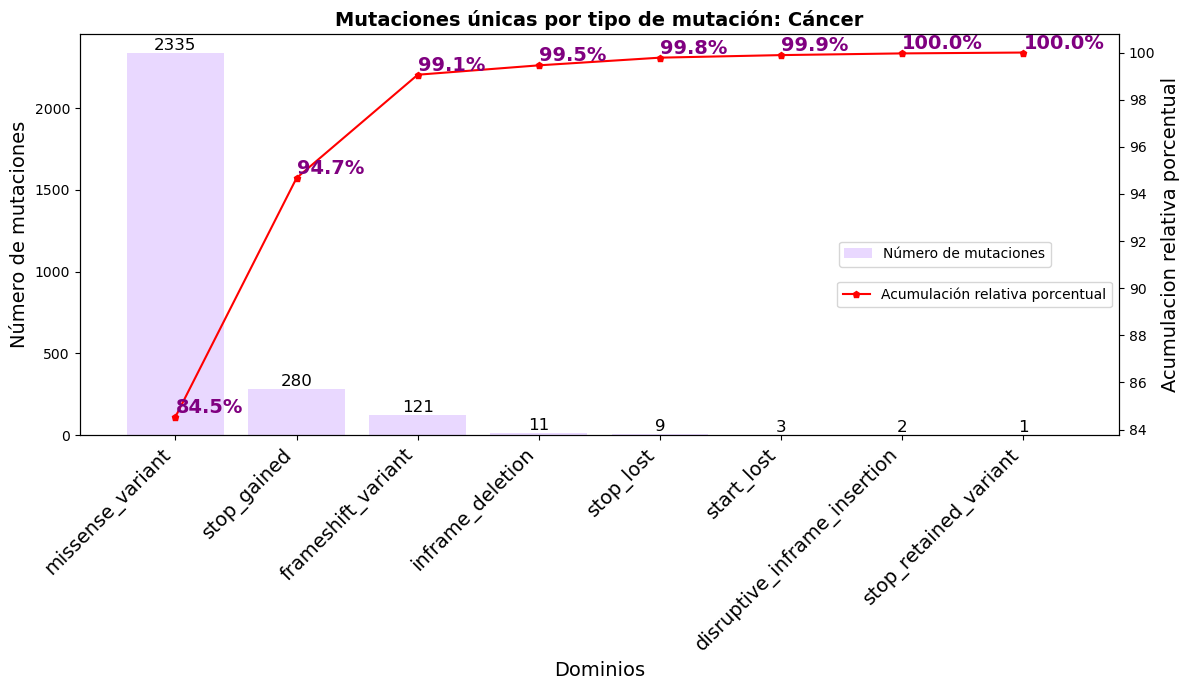

In [32]:
#PARAMETROS GENRALES
df = df_consequence #DATAFRAME A UTILIZAR
count = "aa_mutation" #COLUMNA QUE SE VA A CONTAR O SUMAR (eje Y)
grupo = "consequence_type" #barras
mutation_counts = df.groupby(grupo, as_index=False)[count].nunique() #OPERACION 

#PARAMETROS DE ETIQUETA
ylabel = 'Número de mutaciones' # Etiqueta eje y
ylabel2 = 'Acumulacion relativa porcentual' # Etiqueta eje 2
set_title = 'Mutaciones únicas por tipo de mutación: Cáncer' # Titulo del grafico
set_xlabel = 'Dominios' # Titulo eje X
leyenda_2 = 'Acumulación relativa porcentual' # Nombre leyenda eje 2
leyenda_count = 'Número de mutaciones' # Nombre leyenda eje 1

#PARAMETROS COLORES
color_bar = "#e9d8ffff"
color_linea = "red"
numero_acumulacion = 'purple'

#PARAMETRO DE GUARDADO
GUARDAR_GRAFICO = False
FORMATO_IMAGEN = "png"  # Cambiar a "svg" si se quiere otro formato (png y svg deben estar en minuscula)
DPI = 600  # Se usará solo si FORMATO_IMAGEN == "png"
NOMBRE_IMAGEN = "mut_missense_tgfb"
RUTA = f"../run/imagenes/{NOMBRE_IMAGEN}_.{FORMATO_IMAGEN}"


# Ordenar las mutaciones de mayor a menor
mutation_counts.sort_values(by=count, ascending=False, inplace=True)
mutation_counts.reset_index(drop=True, inplace=True)

# Calcular la acumulación relativa porcentual
mutation_counts['relativa_acum_porcentual'] = mutation_counts[count].cumsum() / mutation_counts[count].sum() * 100

# Crear la figura y los ejes
fig, ax = plt.subplots(figsize=(12, 7))  # Ajusta el tamaño de la figura

# Gráfico de barras para el número de mutaciones
bars = ax.bar(mutation_counts[grupo], mutation_counts[count])

# Gráfico de barras para la cantidad de mutaciones por tipo de cáncer
ax.bar(mutation_counts[grupo], mutation_counts[count], color=color_bar, label=leyenda_count)

# Crear un segundo eje y para la línea de acumulación relativa porcentual
ax2 = ax.twinx()
ax2.plot(mutation_counts.index, mutation_counts['relativa_acum_porcentual'], color=color_linea, marker="p", ms=5, label=leyenda_2)

# Agregar etiquetas con el número de mutaciones encima de las barras
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, height, f'{int(height)}', ha='center', va='bottom', color='black', fontsize=12)

# Agregar etiquetas con el porcentaje acumulado en los puntos de la línea
for i, value in enumerate(mutation_counts["relativa_acum_porcentual"]):
    ax2.text(i, value, f'{value:.1f}%', ha='left', va='bottom', color=numero_acumulacion, fontsize=14,fontweight  = 'bold')
# Ajustar límites y etiquetas
ax.set_ylabel(ylabel, fontsize=14)
ax2.set_ylabel(ylabel2, fontsize=14)
ax.set_title(set_title, fontsize=14, fontweight = "bold")
ax.set_xlabel(set_xlabel, fontsize=14)

# Ajustar las etiquetas del eje x
ax.set_xticks(range(len(mutation_counts[grupo])))  # Colocar las etiquetas en las posiciones correctas
ax.set_xticklabels(mutation_counts[grupo], rotation=45, ha="right", fontsize=14)  # Rotar las etiquetas y alinearlas a la derecha

# Añadir leyendas
ax.legend(loc='best', bbox_to_anchor=(0.941, 0.5))  # Leyenda del primer eje
ax2.legend(loc='best', bbox_to_anchor=(1, 0.4))  # Leyenda del segundo eje, un poco más abajo

# Ajustar el diseño para evitar solapamientos
plt.tight_layout()

# Guardar el gráfico en formato SVG antes de mostrarlo
if GUARDAR_GRAFICO:
    if FORMATO_IMAGEN == "png":
        plt.savefig(RUTA, format="png", dpi=DPI)
    else:
        plt.savefig(RUTA, format=FORMATO_IMAGEN)

plt.show()
